# Dimensionality Reduction & Unsupervised Clustering
### Discovering wine types from 13 chemical measurements

**RabTech Academy · Data Science with Python & R Internship · Task 4**
Author: Dheena Dhayalan P

| | |
|---|---|
| **Dataset** | UCI Wine: 178 wines from one region of Italy, each with 13 chemical measurements (Forina et al., *PARVUS*; UCI ML Repository, CC BY 4.0) |
| **Goal** | Find natural groups in 13-dimensional chemical space **without labels** |
| **Hidden ground truth** | Each wine comes from one of 3 grape cultivars. These labels are **never** used for fitting. They are used only at the end to check whether the discovered clusters are real |

**Roadmap**
1. Load and explore the data
2. Standardize features
3. PCA: scree plot, choosing the number of components, loadings, biplot
4. K-Means: Elbow Method and Silhouette analysis to choose *k*
5. DBSCAN: k-distance plot and parameter search
6. Hierarchical clustering: Ward dendrogram
7. Comparing the algorithms (internal and external validation)
8. 2D and 3D cluster projections (Seaborn, Matplotlib, Plotly)
9. Cluster profiles and findings

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from kneed import KneeLocator
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

SEED = 42
pio.renderers.default = "notebook_connected"
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
CLUSTER_COLORS = ["#2A8C82", "#E07B39", "#8E5BB5", "#3182BD", "#C0392B", "#7F8C8D"]
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Load and explore the data

In [2]:
raw = pd.read_csv("../data/raw/wine.csv")
y_true = raw.pop("cultivar")          # kept aside for external validation only
X_raw = raw
print(f"{X_raw.shape[0]} wines × {X_raw.shape[1]} features | missing values: {X_raw.isna().sum().sum()}")
X_raw.describe().T[["mean", "std", "min", "max"]]

178 wines × 13 features | missing values: 0


,mean,std,min,max
alcohol,13.001,0.812,11.030,14.830
malic_acid,2.336,1.117,0.740,5.800
ash,2.367,0.274,1.360,3.230
alcalinity_of_ash,19.495,3.340,10.600,30.000
magnesium,99.742,14.282,70.000,162.000
total_phenols,2.295,0.626,0.980,3.880
flavanoids,2.029,0.999,0.340,5.080
nonflavanoid_phenols,0.362,0.124,0.130,0.660
proanthocyanins,1.591,0.572,0.410,3.580
color_intensity,5.058,2.318,1.280,13.000


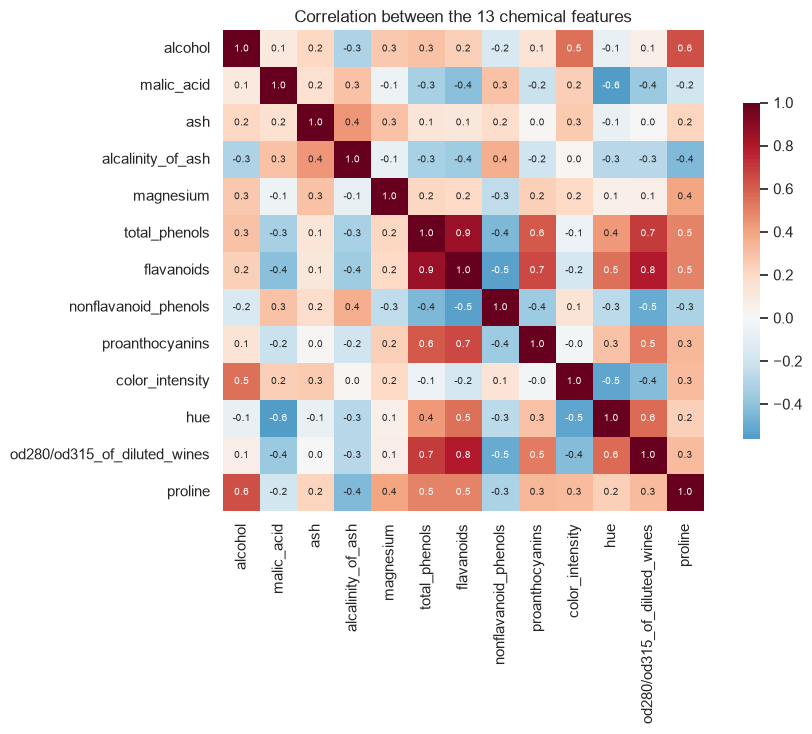

In [3]:
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(X_raw.corr(), cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, square=True, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlation between the 13 chemical features")
plt.tight_layout(); plt.savefig(FIG / "01_correlation.png", dpi=150); plt.show()

Many features are strongly correlated. For example, `flavanoids`, `total_phenols` and
`od280/od315` all move together (r ≈ 0.7–0.9). This redundancy is what PCA exploits: a few
components can capture most of the information.

## 2. Standardize the features

The features are on very different scales. `proline` ranges up to about 1,680, while `hue`
stays below 2. PCA and distance-based clustering would be dominated by the large-scale
features, so every feature is transformed to **z-scores** (mean 0, SD 1) with
`StandardScaler`.

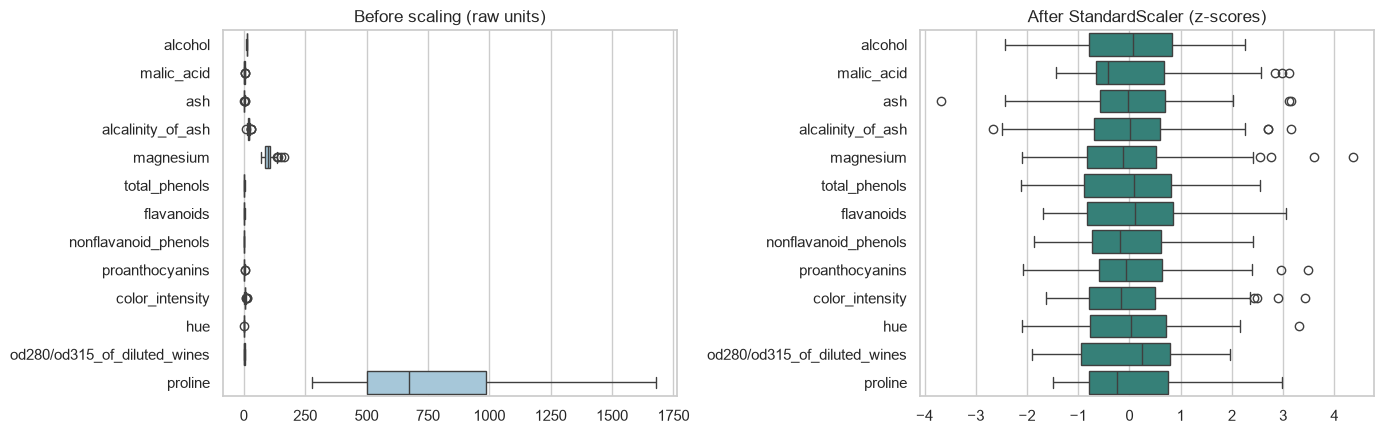

Means after scaling ≈ 0: True | SDs = 1: True


In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(X_raw, orient="h", ax=axes[0], color="#9ECAE1"); axes[0].set_title("Before scaling (raw units)")
sns.boxplot(pd.DataFrame(X, columns=X_raw.columns), orient="h", ax=axes[1], color="#2A8C82")
axes[1].set_title("After StandardScaler (z-scores)")
plt.tight_layout(); plt.savefig(FIG / "02_scaling.png", dpi=150); plt.show()
print("Means after scaling ≈ 0:", np.allclose(X.mean(0), 0), "| SDs = 1:", np.allclose(X.std(0), 1))

## 3. Principal Component Analysis

In [5]:
pca_full = PCA(random_state=SEED).fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
eig = pca_full.explained_variance_
pca_table = pd.DataFrame({"PC": [f"PC{i}" for i in range(1, 14)], "eigenvalue": eig,
                          "explained variance": evr, "cumulative": cum})
pca_table

,PC,eigenvalue,explained variance,cumulative
0,PC1,4.732,0.362,0.362
1,PC2,2.511,0.192,0.554
2,PC3,1.454,0.111,0.665
3,PC4,0.924,0.071,0.736
4,PC5,0.858,0.066,0.802
5,PC6,0.645,0.049,0.851
6,PC7,0.554,0.042,0.893
7,PC8,0.350,0.027,0.920
8,PC9,0.291,0.022,0.942
9,PC10,0.252,0.019,0.962


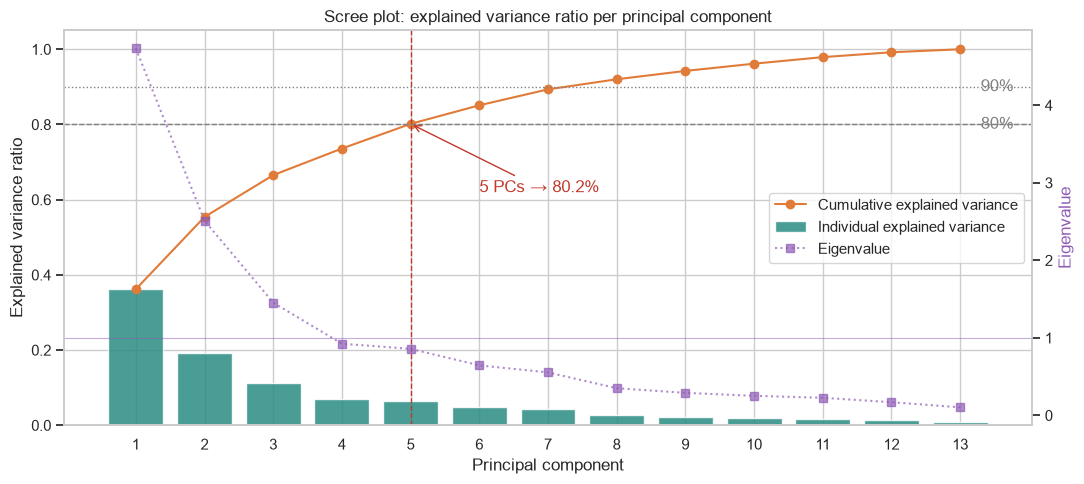

In [6]:
pcs = np.arange(1, 14)
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(pcs, evr, color="#2A8C82", alpha=.85, label="Individual explained variance")
ax.plot(pcs, cum, "o-", color="#E07B39", label="Cumulative explained variance")
for thr, ls in [(0.80, "--"), (0.90, ":")]:
    ax.axhline(thr, color="grey", ls=ls, lw=1)
    ax.text(13.3, thr, f"{thr:.0%}", va="center", color="grey")
n80 = int(np.argmax(cum >= 0.80) + 1)
ax.axvline(n80, color="#C0392B", ls="--", lw=1)
ax.annotate(f"{n80} PCs → {cum[n80-1]:.1%}", (n80, cum[n80-1]), xytext=(n80 + 1, 0.62),
            arrowprops=dict(arrowstyle="->", color="#C0392B"), color="#C0392B")
ax2 = ax.twinx(); ax2.plot(pcs, eig, "s:", color="#8E5BB5", alpha=.7, label="Eigenvalue")
ax2.axhline(1, color="#8E5BB5", lw=.8, alpha=.5); ax2.set_ylabel("Eigenvalue", color="#8E5BB5"); ax2.grid(False)
ax.set(xlabel="Principal component", ylabel="Explained variance ratio", xticks=pcs,
       title="Scree plot: explained variance ratio per principal component")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout(); plt.savefig(FIG / "03_scree_plot.png", dpi=150); plt.show()

In [7]:
kaiser = int((eig > 1).sum())
elbow_pc = KneeLocator(pcs, evr, curve="convex", direction="decreasing").knee
print(f"Kaiser criterion (eigenvalue > 1):   {kaiser} components ({cum[kaiser-1]:.1%} of variance)")
print(f"Scree elbow (kneedle algorithm):     {elbow_pc} components ({cum[elbow_pc-1]:.1%})")
print(f"≥ 80% cumulative variance:           {n80} components ({cum[n80-1]:.1%})")

Kaiser criterion (eigenvalue > 1):   3 components (66.5% of variance)
Scree elbow (kneedle algorithm):     4 components (73.6%)
≥ 80% cumulative variance:           5 components (80.2%)


**Choosing the number of components.** There are three standard rules:

| Rule | Components | Variance kept |
|---|---|---|
| Kaiser (eigenvalue > 1) | 3 | 66.5% |
| Scree elbow (kneedle) | 4 | 73.6% |
| ≥ 80% cumulative variance | **5** | **80.2%** |

We keep **5 components (80.2% of the variance)** as the space used for clustering. It cuts the
dimensions from 13 to 5 and drops the noisy low-variance directions, while keeping most of the
signal. PC1–PC3 (66.5%) are used for the 2D and 3D visualisations.

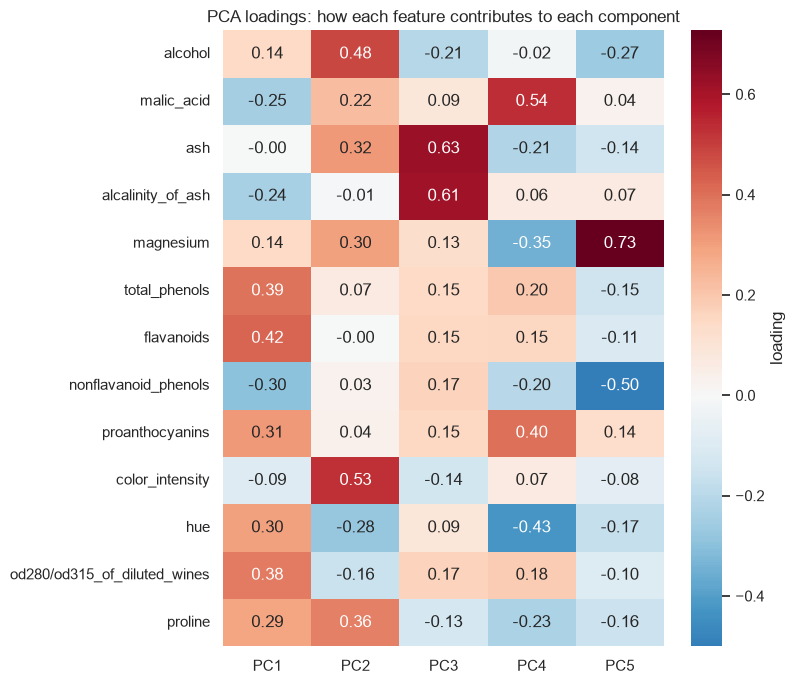

In [8]:
N_PC = n80
pca = PCA(n_components=N_PC, random_state=SEED)
Z = pca.fit_transform(X)
loadings = pd.DataFrame(pca.components_.T, index=X_raw.columns,
                        columns=[f"PC{i}" for i in range(1, N_PC + 1)])
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "loading"})
ax.set_title("PCA loadings: how each feature contributes to each component")
plt.tight_layout(); plt.savefig(FIG / "04_loadings.png", dpi=150); plt.show()

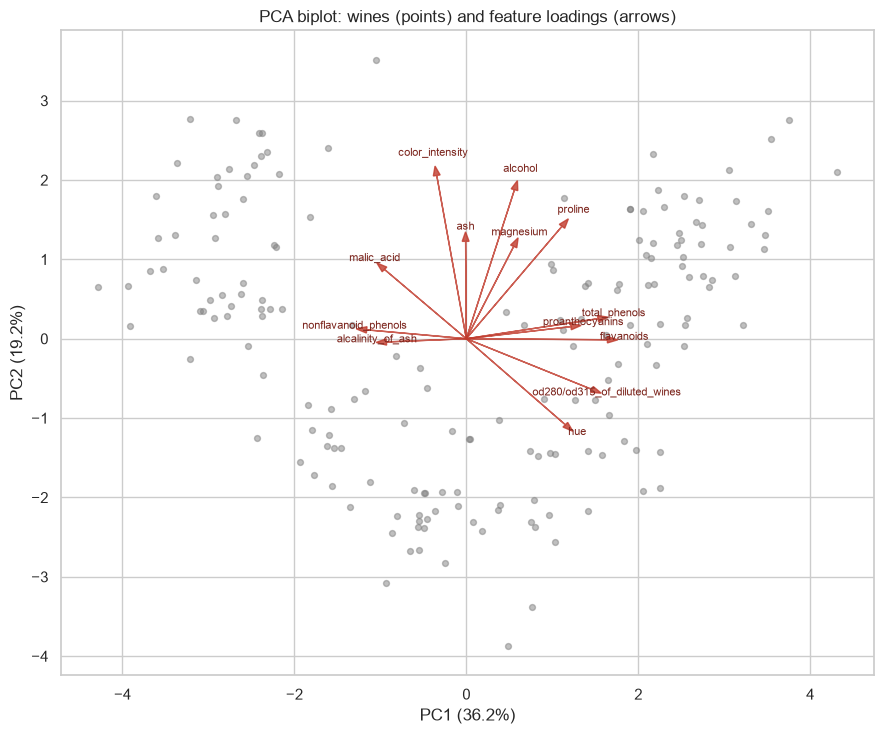

In [9]:
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.scatter(Z[:, 0], Z[:, 1], s=18, c="grey", alpha=.5)
scale = np.abs(Z[:, :2]).max() * .9
for feat, (l1, l2) in loadings[["PC1", "PC2"]].iterrows():
    ax.arrow(0, 0, l1 * scale, l2 * scale, color="#C0392B", alpha=.8, head_width=.08)
    ax.text(l1 * scale * 1.12, l2 * scale * 1.12, feat, fontsize=8, ha="center", color="#7B241C")
ax.set(xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})",
       title="PCA biplot: wines (points) and feature loadings (arrows)")
plt.tight_layout(); plt.savefig(FIG / "05_biplot.png", dpi=150); plt.show()

**Interpreting the components**
- **PC1 (36.2%)** is a *phenolic richness* axis. `flavanoids`, `total_phenols`, `od280/od315` and
  `proanthocyanins` load positively, and `nonflavanoid_phenols` and `alcalinity_of_ash` load
  negatively.
- **PC2 (19.2%)** is an *intensity and body* axis, driven by `color_intensity`, `alcohol`,
  `proline` and `ash`.

Even with no labels, the biplot already shows the points forming several clouds.

## 4. K-Means: choosing *k*

Two complementary criteria are used, on the 5-component PCA space, for *k* = 2…10:

- **Elbow Method:** inertia (the within-cluster sum of squares) always falls as *k* grows. The
  "elbow" is where adding a cluster stops giving a large drop.
- **Silhouette Score:** for each point, s = (b − a) / max(a, b), where *a* is the mean distance
  to its own cluster and *b* is the mean distance to the nearest other cluster. It ranges from
  −1 to 1, and higher means tighter, better-separated clusters.

In [10]:
K = range(2, 11)
rows = []
for k in K:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(Z, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(Z, km.labels_),
                 "Calinski-Harabasz": calinski_harabasz_score(Z, km.labels_)})
k_scores = pd.DataFrame(rows).set_index("k")
elbow_k = KneeLocator(list(K), k_scores["inertia"], curve="convex", direction="decreasing").knee
best_sil_k = int(k_scores["silhouette"].idxmax())
print(f"Elbow (kneedle): k = {elbow_k}  |  Best silhouette: k = {best_sil_k} "
      f"(s = {k_scores.loc[best_sil_k, 'silhouette']:.3f})")
k_scores

Elbow (kneedle): k = 4  |  Best silhouette: k = 3 (s = 0.369)


,inertia,silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,"1,201.158",0.324,1.275,95.798
3,825.021,0.369,1.093,109.233
4,723.936,0.326,1.419,90.615
5,661.429,0.308,1.325,78.043
6,605.376,0.273,1.337,71.006
7,558.114,0.276,1.360,66.223
8,516.235,0.245,1.321,62.979
9,474.107,0.224,1.285,61.527
10,446.189,0.221,1.369,58.937


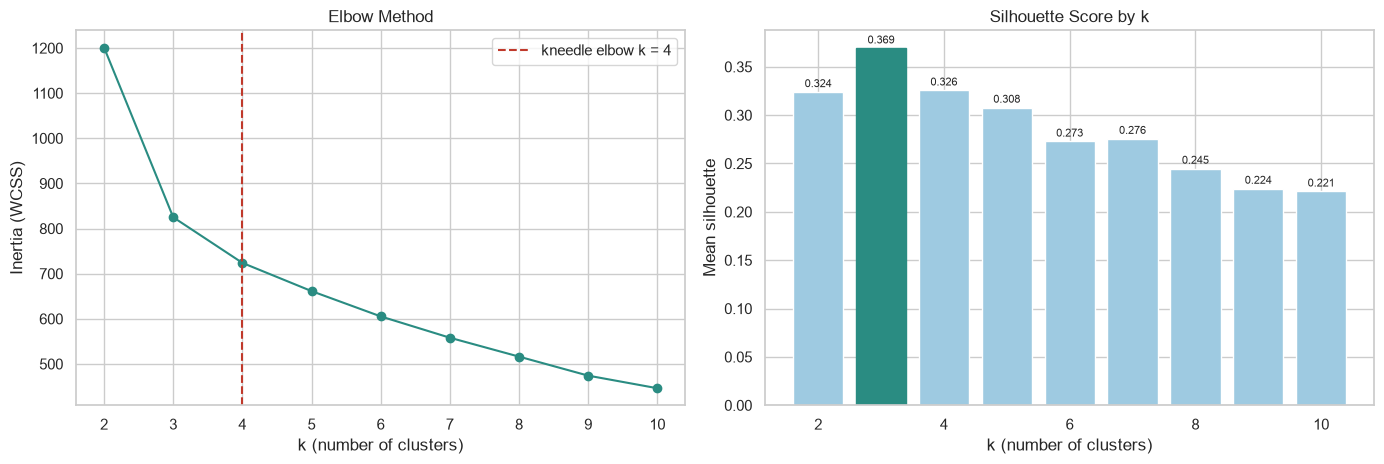

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(k_scores.index, k_scores["inertia"], "o-", color="#2A8C82")
axes[0].axvline(elbow_k, color="#C0392B", ls="--", label=f"kneedle elbow k = {elbow_k}")
axes[0].set(title="Elbow Method", xlabel="k (number of clusters)", ylabel="Inertia (WCSS)")
axes[0].legend()
bars = axes[1].bar(k_scores.index, k_scores["silhouette"], color="#9ECAE1")
bars[best_sil_k - 2].set_color("#2A8C82")
for k, s in k_scores["silhouette"].items():
    axes[1].text(k, s + .005, f"{s:.3f}", ha="center", fontsize=8)
axes[1].set(title="Silhouette Score by k", xlabel="k (number of clusters)", ylabel="Mean silhouette")
plt.tight_layout(); plt.savefig(FIG / "06_elbow_silhouette.png", dpi=150); plt.show()

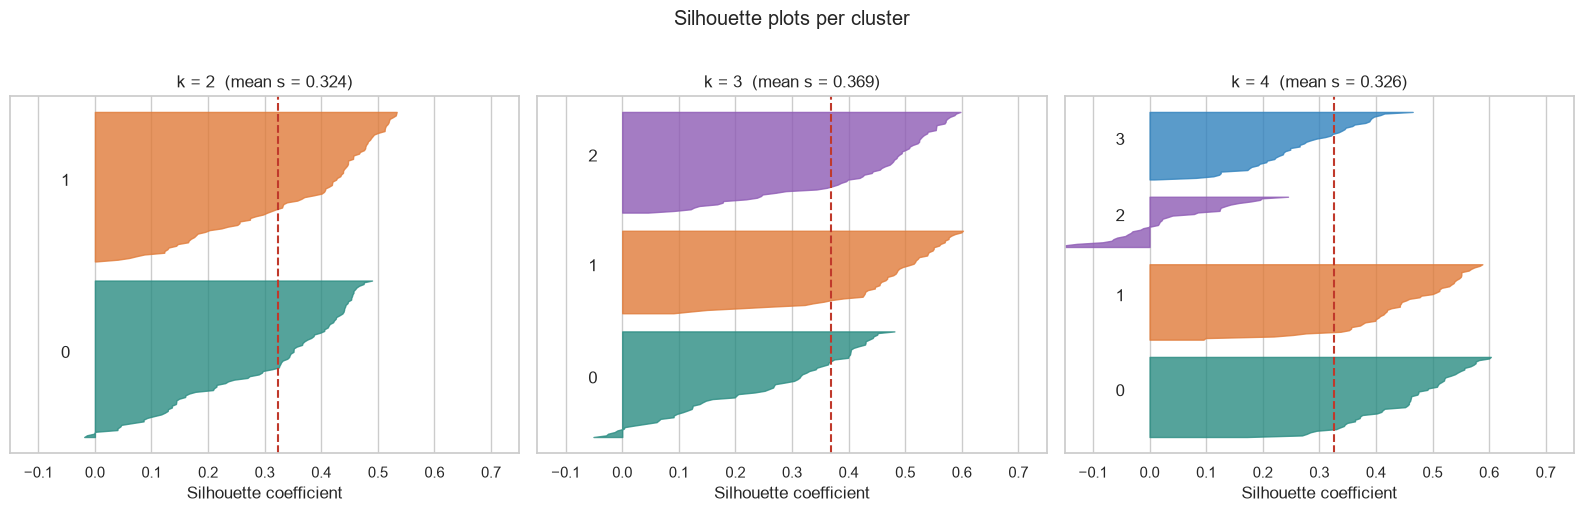

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z)
    s = silhouette_samples(Z, lab); y0 = 10
    for c in range(k):
        sc = np.sort(s[lab == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, color=CLUSTER_COLORS[c], alpha=.8)
        ax.text(-0.06, y0 + len(sc) / 2, str(c)); y0 += len(sc) + 10
    ax.axvline(s.mean(), color="#C0392B", ls="--")
    ax.set(title=f"k = {k}  (mean s = {s.mean():.3f})", xlabel="Silhouette coefficient", yticks=[],
           xlim=(-0.15, 0.75))
fig.suptitle("Silhouette plots per cluster", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "07_silhouette_plots.png", dpi=150, bbox_inches="tight"); plt.show()

**Decision: k = 3.**
- The **silhouette score peaks at k = 3** (0.369, against 0.324 for k = 2 and 0.326 for k = 4).
  The silhouette plot for k = 3 has three thick clusters of similar size with almost no
  negative values (few badly assigned wines).
- The **elbow is ambiguous.** The biggest drop in inertia is from k = 2 to k = 3 (1,201 → 825),
  but the kneedle algorithm puts the elbow at k = 4. When the elbow is unclear, the silhouette
  score is the better tie-breaker.
- **Davies-Bouldin is lowest (1.09) and Calinski-Harabasz is highest (109) at k = 3**, so three
  independent criteria agree.

In [13]:
K_BEST = 3
kmeans = KMeans(n_clusters=K_BEST, n_init=20, random_state=SEED).fit(Z)
labels_km = kmeans.labels_
pd.Series(labels_km).value_counts().sort_index().rename("wines per cluster").to_frame().T

,0,1,2
wines per cluster,65,51,62


## 5. DBSCAN: density-based clustering

DBSCAN does not need *k*. Instead it groups points that have at least `min_samples`
neighbours within radius `eps`, and labels isolated points as **noise (−1)**.

- `min_samples` follows the common rule of thumb **2 × dimensions = 10**.
- `eps` is read from the **k-distance plot**, which sorts each point's distance to its 10th
  nearest neighbour. The knee of that curve is a natural density threshold.

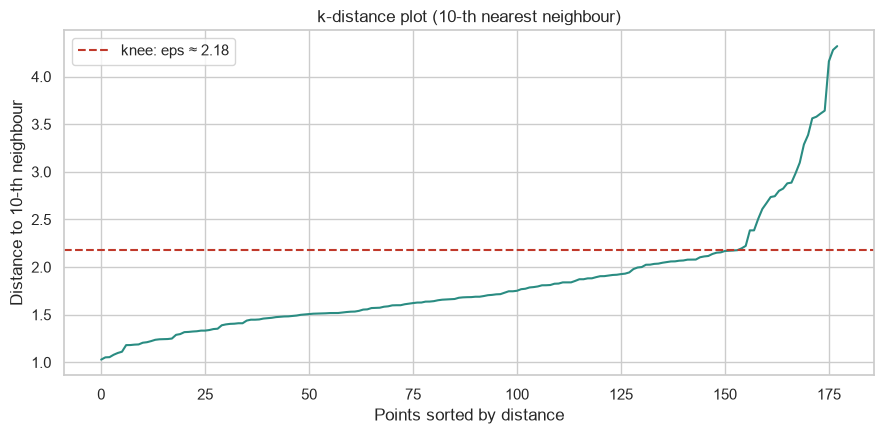

In [14]:
MIN_SAMPLES = 2 * N_PC
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
knee = KneeLocator(range(len(kdist)), kdist, curve="convex", direction="increasing").knee
EPS_KNEE = kdist[knee]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(kdist, color="#2A8C82"); ax.axhline(EPS_KNEE, color="#C0392B", ls="--",
                                          label=f"knee: eps ≈ {EPS_KNEE:.2f}")
ax.set(title=f"k-distance plot ({MIN_SAMPLES}-th nearest neighbour)",
       xlabel="Points sorted by distance", ylabel=f"Distance to {MIN_SAMPLES}-th neighbour")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "08_k_distance.png", dpi=150); plt.show()

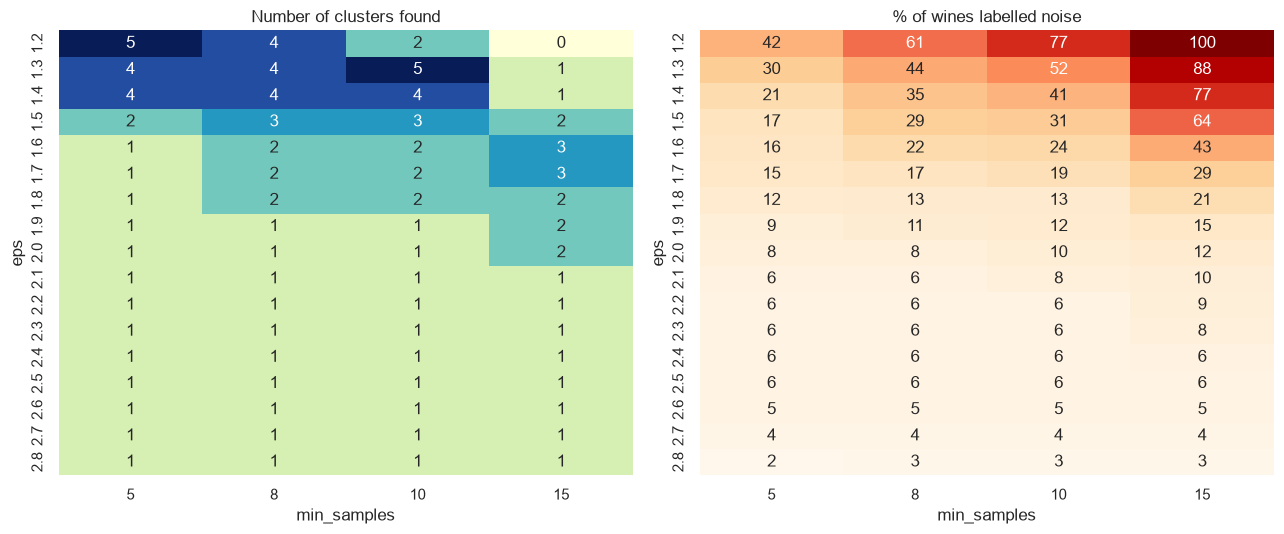

In [15]:
grid = []
for ms in [5, 8, 10, 15]:
    for eps in np.round(np.arange(1.2, 2.81, 0.1), 2):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        core = lab != -1
        n_cl = len(set(lab[core]))
        grid.append({"min_samples": ms, "eps": eps, "clusters": n_cl,
                     "noise %": 100 * (~core).mean(),
                     "silhouette (non-noise)": silhouette_score(Z[core], lab[core]) if n_cl > 1 else np.nan})
grid = pd.DataFrame(grid)
pivot = grid.pivot(index="eps", columns="min_samples", values="clusters")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title("Number of clusters found")
sns.heatmap(grid.pivot(index="eps", columns="min_samples", values="noise %"), annot=True, fmt=".0f",
            cmap="OrRd", ax=axes[1], cbar=False)
axes[1].set_title("% of wines labelled noise")
plt.tight_layout(); plt.savefig(FIG / "09_dbscan_grid.png", dpi=150); plt.show()

In [16]:
viable = grid[(grid["clusters"] >= 2) & (grid["noise %"] <= 30)]
best_db = viable.sort_values("silhouette (non-noise)", ascending=False).iloc[0]
print("At the k-distance knee:",
      grid.iloc[(grid[grid.min_samples == MIN_SAMPLES]["eps"] - EPS_KNEE).abs().argsort()[:1].values]
      [["min_samples", "eps", "clusters", "noise %"]].to_dict("records"))
print("Best viable setting (≥2 clusters, ≤30% noise, highest silhouette):")
best_db.to_frame().T

At the k-distance knee: [{'min_samples': 5, 'eps': 2.2, 'clusters': 1, 'noise %': 5.617977528089887}]
Best viable setting (≥2 clusters, ≤30% noise, highest silhouette):


,min_samples,eps,clusters,noise %,silhouette (non-noise)
56,15.000,1.700,3.000,28.652,0.492


In [17]:
dbscan = DBSCAN(eps=best_db["eps"], min_samples=int(best_db["min_samples"])).fit(Z)
labels_db = dbscan.labels_
pd.Series(labels_db).value_counts().sort_index().rename("wines").to_frame().T

,-1,0,1,2
wines,51,57,37,33


**DBSCAN is a poor fit for this dataset, and the reason is informative.**
At the k-distance knee (eps ≈ 2.2), DBSCAN merges almost everything into **one** cluster. Its
best setting that still finds clusters (eps = 1.7, min_samples = 15) does find 3 clusters, but
only by labelling **51 wines (29%) as noise**. The three
wine groups have **similar density and touch at their edges** in PCA space (see the biplot), so
there is no low-density "gap" for DBSCAN to cut along. DBSCAN does best with arbitrarily shaped
clusters that are separated by sparse regions. K-Means and Ward assume compact, roughly
spherical groups, which matches this data.

## 6. Hierarchical clustering (Ward linkage)

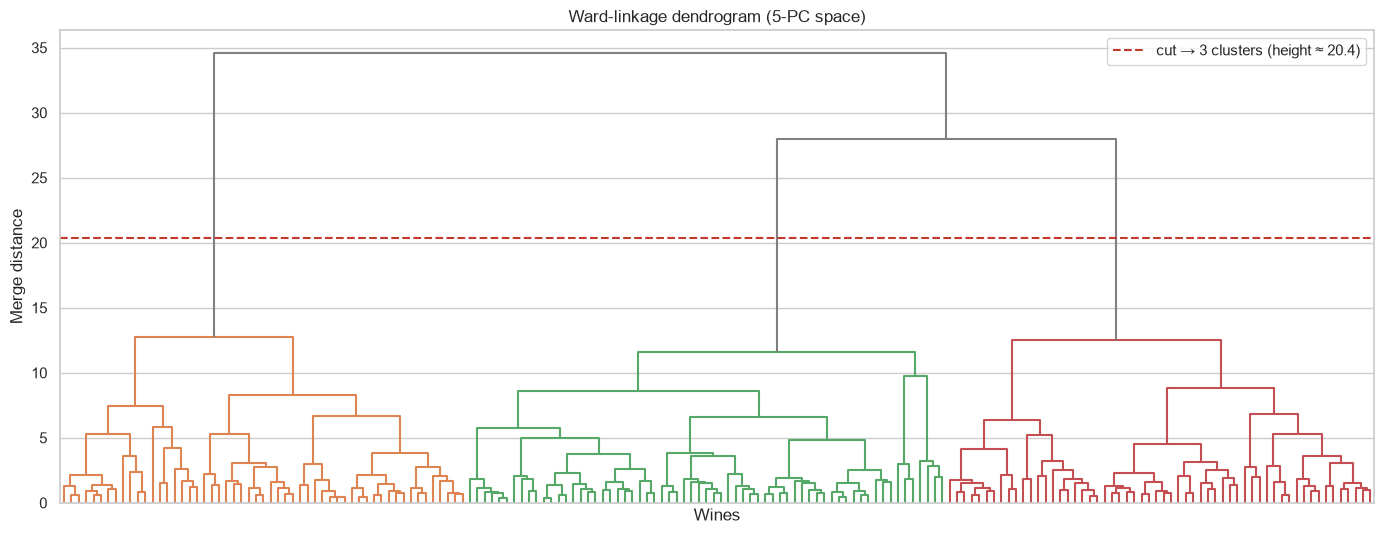

In [18]:
Lk = linkage(Z, method="ward")
fig, ax = plt.subplots(figsize=(14, 5.5))
cut = (Lk[-3, 2] + Lk[-2, 2]) / 2   # height that leaves exactly 3 clusters
dendrogram(Lk, ax=ax, color_threshold=cut, no_labels=True, above_threshold_color="grey")
ax.axhline(cut, color="#C0392B", ls="--", label=f"cut → 3 clusters (height ≈ {cut:.1f})")
ax.set(title="Ward-linkage dendrogram (5-PC space)", ylabel="Merge distance", xlabel="Wines")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "10_dendrogram.png", dpi=150); plt.show()

In [19]:
hc_scores = []
for k in range(2, 7):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    hc_scores.append({"k": k, "silhouette": silhouette_score(Z, lab)})
display(pd.DataFrame(hc_scores).set_index("k").T)
labels_hc = AgglomerativeClustering(n_clusters=K_BEST, linkage="ward").fit_predict(Z)

k,2,3,4,5,6
silhouette,0.323,0.347,0.291,0.268,0.281


The dendrogram has a long vertical gap just below the top merges. Cutting it there gives
**3 clusters**, the same number K-Means chose, and Ward's silhouette also peaks at k = 3. Two
different algorithms agreeing is good evidence that the 3-group structure is real.

## 7. Comparing the algorithms

**Internal metrics** use only the data: silhouette ↑, Davies-Bouldin ↓, Calinski-Harabasz ↑.
**External metrics** compare the clusters to the hidden cultivar labels, which were never used
in fitting:
- **ARI (Adjusted Rand Index):** 1 means perfect agreement and 0 means no better than random.
- **NMI (normalized mutual information):** 1 means perfect agreement and 0 means unrelated.

For DBSCAN, the internal metrics are computed on non-noise points only, and noise counts as its
own group for ARI and NMI.

In [20]:
def scores(name, lab):
    core = lab != -1
    return {"algorithm": name, "clusters": len(set(lab[core])), "noise points": int((~core).sum()),
            "silhouette": silhouette_score(Z[core], lab[core]),
            "Davies-Bouldin": davies_bouldin_score(Z[core], lab[core]),
            "Calinski-Harabasz": calinski_harabasz_score(Z[core], lab[core]),
            "ARI vs cultivar": adjusted_rand_score(y_true, lab),
            "NMI vs cultivar": normalized_mutual_info_score(y_true, lab)}

comparison = pd.DataFrame([scores("K-Means (k=3)", labels_km),
                           scores("Hierarchical Ward (k=3)", labels_hc),
                           scores(f"DBSCAN (eps={best_db['eps']}, min_samples={int(best_db['min_samples'])})", labels_db)]
                          ).set_index("algorithm")
comparison

,clusters,noise points,silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs cultivar,NMI vs cultivar
algorithm,,,,,,,
K-Means (k=3),3,0,0.369,1.093,109.233,0.897,0.876
Hierarchical Ward (k=3),3,0,0.347,1.105,100.021,0.761,0.749
"DBSCAN (eps=1.7, min_samples=15)",3,51,0.492,0.766,159.514,0.562,0.624


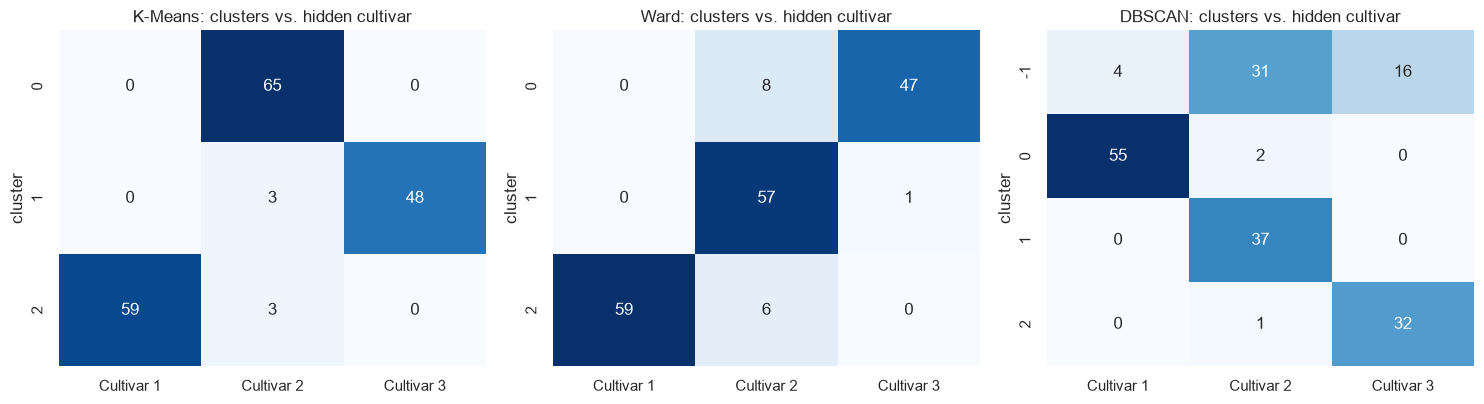

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, lab) in zip(axes, [("K-Means", labels_km), ("Ward", labels_hc), ("DBSCAN", labels_db)]):
    ct = pd.crosstab(pd.Series(lab, name="cluster"), pd.Series(y_true.map({0: "Cultivar 1", 1: "Cultivar 2", 2: "Cultivar 3"}), name=""))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name}: clusters vs. hidden cultivar")
plt.tight_layout(); plt.savefig(FIG / "11_confusion_vs_cultivar.png", dpi=150); plt.show()

**Reading the comparison**
- **K-Means is the best overall.** Its ARI is **0.90** against the hidden cultivars: the
  confusion matrix shows **172 of 178 wines (96.6%)** landing with their own cultivar, even
  though cultivar was never used. All 6 misplaced wines belong to cultivar 2, which sits
  between the other two in PCA space.
- **Ward is a close second** (ARI 0.76). It mixes more cultivar-2 wines into neighbouring
  clusters.
- **DBSCAN's internal scores look best, but that's misleading.** It sets aside the 51 hardest
  wines as noise and scores only the easy core points. Judged against the cultivars, it is
  clearly the weakest (ARI 0.56). This is why internal metrics should not be compared directly
  when one algorithm can discard points.

## 8. Cluster projections in 2D and 3D

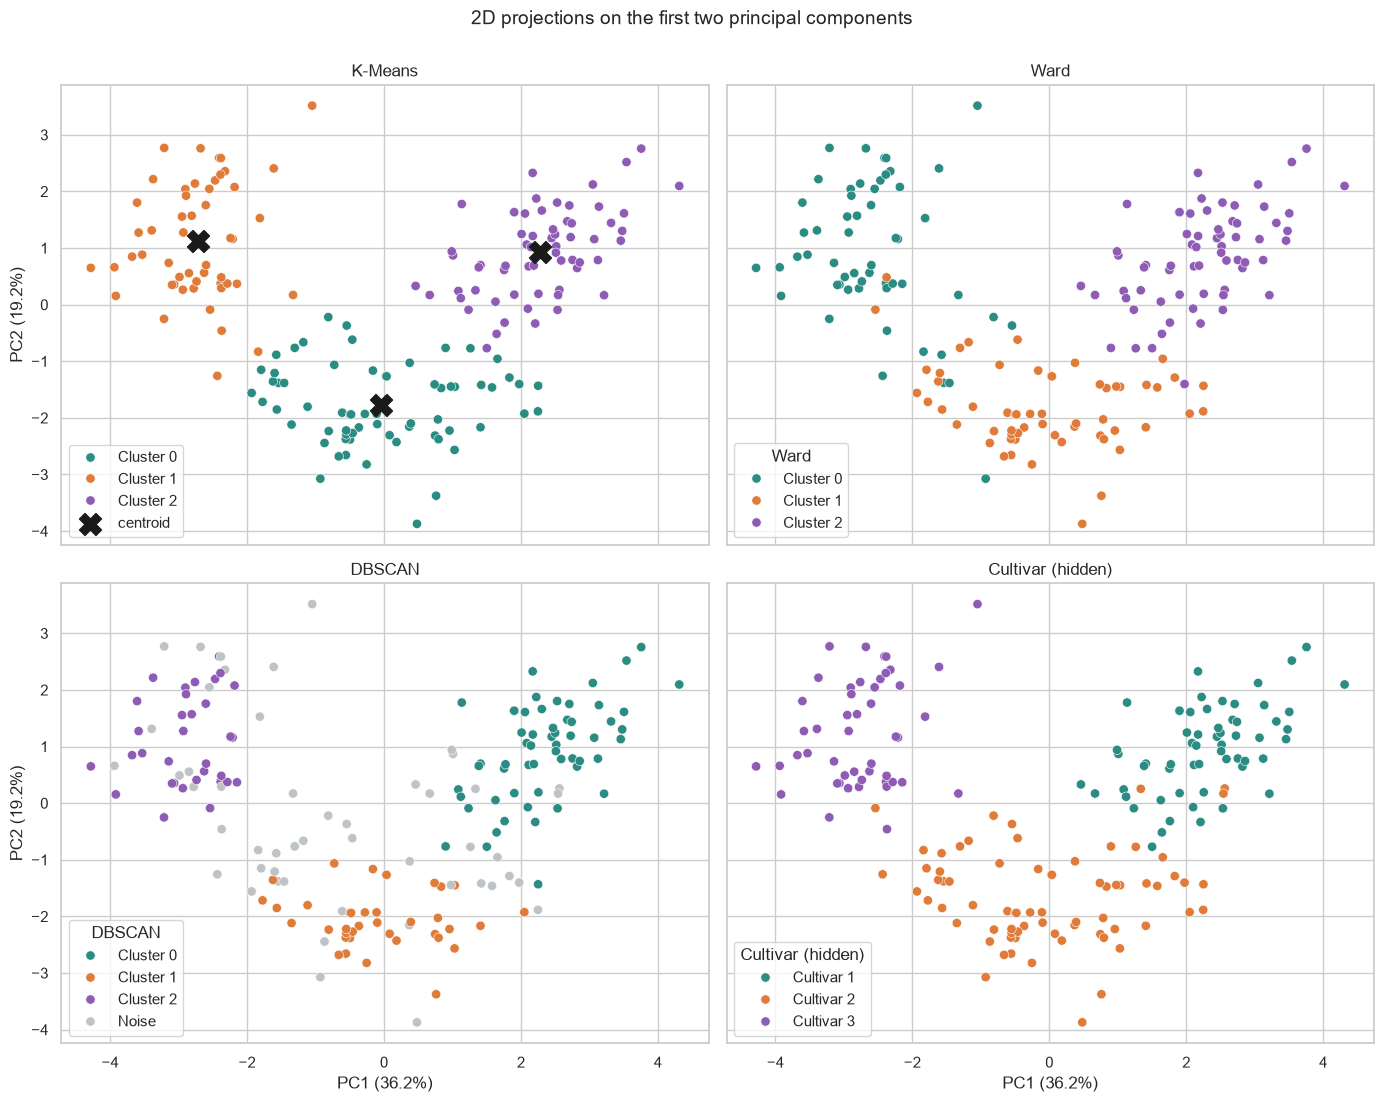

In [22]:
proj = pd.DataFrame(Z[:, :3], columns=["PC1", "PC2", "PC3"])
proj["K-Means"] = [f"Cluster {c}" for c in labels_km]
proj["Ward"] = [f"Cluster {c}" for c in labels_hc]
proj["DBSCAN"] = ["Noise" if c == -1 else f"Cluster {c}" for c in labels_db]
proj["Cultivar (hidden)"] = [f"Cultivar {c + 1}" for c in y_true]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
for ax, col in zip(axes.flat, ["K-Means", "Ward", "DBSCAN", "Cultivar (hidden)"]):
    order = sorted(proj[col].unique())
    pal = {lvl: ("#BDC3C7" if lvl == "Noise" else CLUSTER_COLORS[i]) for i, lvl in enumerate(order)}
    sns.scatterplot(proj, x="PC1", y="PC2", hue=col, hue_order=order, palette=pal, s=45,
                    edgecolor="white", linewidth=.4, ax=ax)
    if col == "K-Means":
        cent = kmeans.cluster_centers_
        ax.scatter(cent[:, 0], cent[:, 1], marker="X", s=250, c="k", label="centroid")
        ax.legend()
    ax.set_title(col)
for ax in axes[-1]: ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
for ax in axes[:, 0]: ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
fig.suptitle("2D projections on the first two principal components", y=1.0, fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "12_projections_2d.png", dpi=150); plt.show()

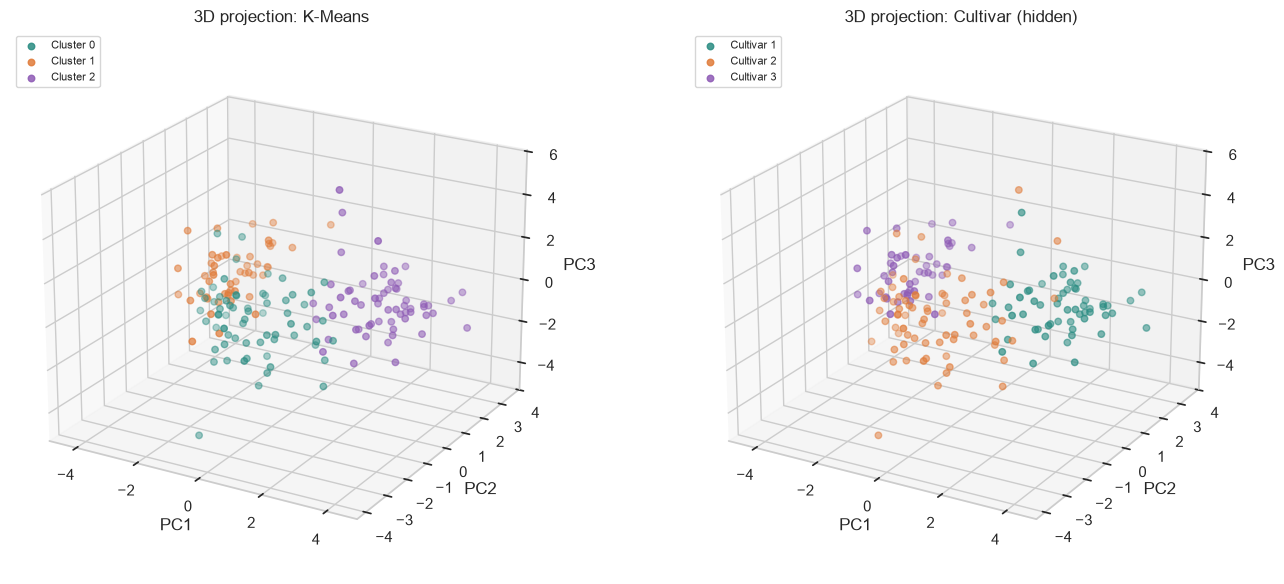

In [23]:
fig = plt.figure(figsize=(14, 6))
for i, col in enumerate(["K-Means", "Cultivar (hidden)"]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    for j, lvl in enumerate(sorted(proj[col].unique())):
        m = proj[col] == lvl
        ax.scatter(proj.PC1[m], proj.PC2[m], proj.PC3[m], s=22, color=CLUSTER_COLORS[j], label=lvl, alpha=.85)
    ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title=f"3D projection: {col}")
    ax.view_init(elev=22, azim=-60); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "13_projection_3d.png", dpi=150); plt.show()

In [24]:
fig3d = px.scatter_3d(proj, x="PC1", y="PC2", z="PC3", color="K-Means", symbol="Cultivar (hidden)",
                      color_discrete_sequence=CLUSTER_COLORS, opacity=.85,
                      title="Interactive 3D PCA projection: K-Means clusters (colour) vs cultivar (symbol)",
                      labels={"PC1": f"PC1 ({evr[0]:.0%})", "PC2": f"PC2 ({evr[1]:.0%})", "PC3": f"PC3 ({evr[2]:.0%})"})
fig3d.update_traces(marker_size=4)
fig3d.update_layout(height=600, legend_title_text="cluster, cultivar")
fig3d.write_html("../reports/interactive_3d_clusters.html", include_plotlyjs="cdn")
fig3d.show()

> The interactive Plotly chart doesn't display on GitHub's notebook preview. Open
> `reports/interactive_3d_clusters.html` in a browser, or view this notebook through nbviewer,
> to rotate it. The static 3D Matplotlib version is shown above.

## 9. Cluster profiles: what makes each group different?

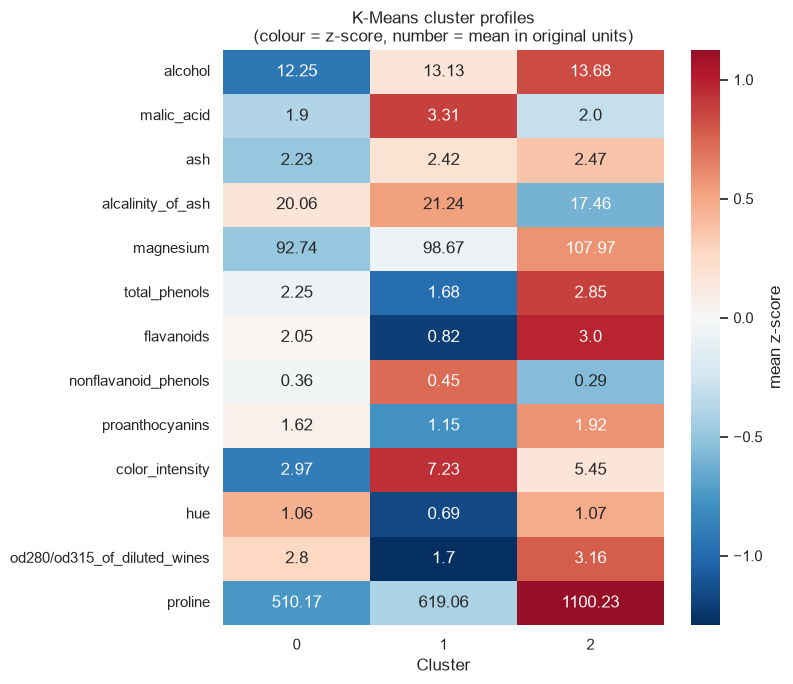

In [25]:
profile = X_raw.assign(cluster=labels_km).groupby("cluster").mean().T
z_profile = pd.DataFrame(X, columns=X_raw.columns).assign(cluster=labels_km).groupby("cluster").mean().T
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(z_profile, cmap="RdBu_r", center=0, annot=profile.round(2).values, fmt="", ax=ax,
            cbar_kws={"label": "mean z-score"})
ax.set(title="K-Means cluster profiles\n(colour = z-score, number = mean in original units)", xlabel="Cluster", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "14_cluster_profiles.png", dpi=150); plt.show()

In [26]:
for c in range(K_BEST):
    top = z_profile[c].sort_values()
    print(f"Cluster {c} (n={int((labels_km == c).sum())}): "
          f"HIGH {', '.join(top.index[-3:][::-1])}  |  LOW {', '.join(top.index[:3])}")

Cluster 0 (n=65): HIGH hue, od280/od315_of_diluted_wines, alcalinity_of_ash  |  LOW alcohol, color_intensity, proline
Cluster 1 (n=51): HIGH color_intensity, malic_acid, nonflavanoid_phenols  |  LOW od280/od315_of_diluted_wines, flavanoids, hue
Cluster 2 (n=62): HIGH proline, flavanoids, total_phenols  |  LOW alcalinity_of_ash, nonflavanoid_phenols, malic_acid


**Three distinct chemical profiles**

| Cluster | n | Chemical signature | Matches hidden |
|---|---|---|---|
| **2** | 62 | **High proline, flavanoids, total phenols, alcohol.** Rich, full-bodied wines | Cultivar 1 |
| **0** | 65 | **Low alcohol, colour intensity, proline.** Light wines with high hue | Cultivar 2 |
| **1** | 51 | **High colour intensity and malic acid, low flavanoids and hue.** Deep-coloured but phenol-poor | Cultivar 3 |

Each cluster is a coherent, interpretable wine style, not just a geometric partition.

## 10. Findings

| Step | Result |
|---|---|
| **Standardization** | Required: feature scales differ by about 1000× (`proline` vs `hue`) |
| **PCA** | PC1 = phenolic richness (36.2%), PC2 = colour intensity and alcohol (19.2%). **5 PCs keep 80.2%** of the variance (13 → 5 dims). Kaiser's rule keeps 3 (66.5%) |
| **Optimal k** | **Silhouette peaks at k = 3 (0.369).** Davies-Bouldin and Calinski-Harabasz agree. The elbow is ambiguous (kneedle says 4) |
| **K-Means (k = 3)** | Clusters of 65 / 51 / 62 wines. **ARI 0.90, NMI 0.88** vs the hidden cultivars |
| **Hierarchical (Ward)** | Independently gives 3 clusters at the largest dendrogram gap. ARI 0.76 |
| **DBSCAN** | One cluster at the k-distance knee. The best tuning gives 3 clusters but 29% noise, ARI 0.56. The groups have similar density and no sparse gap between them |
| **Profiles** | Rich/high-proline · light/low-alcohol · deep-colour/low-phenol, one per cultivar |

**Conclusions**
1. Thirteen correlated chemical measurements can be compressed into about 5 principal
   components with little loss of information. Two axes, phenolic richness and colour/alcohol,
   carry most of the structure.
2. The data contains **three natural wine groups**. Two independent algorithms find them, and
   they correspond to the three grape cultivars **even though the labels were never used**.
3. **The algorithm should suit the cluster shape.** Centroid- and variance-based methods
   (K-Means, Ward) fit these compact, similar-density groups. DBSCAN would suit irregular
   groups separated by sparse regions, which this data does not have.

**Limitations**
- 178 samples is a small dataset.
- K-Means assumes roughly spherical clusters of similar size.
- The PCA cut-off (80% variance) is a convention. The same conclusions hold with 2, 3 or all
  13 dimensions, as checked during exploration.